In [12]:
import seaborn as sns
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier

## **EXERCISE: KNN**

**Gunakan dataset 'cancer'**

- Pada latihan ini, kita sebagai data scientist di bidang kedokteran diminta untuk menentukan apakah sebuah tumor merupakan kanker ganas (malignant) atau jinak (benign)

- Untuk simplifikasi, kita hanya akan menggunakan 2 feature:
    - Features: 'texture_mean' dan 'concave points_mean'
    - Target: 'diagnosis'
<br><br>

- Buat kolom baru yang berasal dari kolom diagnosis. Ubah dari string menjadi integer 
    - malignant --> 1
    - benign --> 0
<br><br>

- Lakukan splitting pada dataset dengan:
    - 20% test set 
    - random_state = 42
<br><br>

- Lakukan modeling dengan KNN   
- Temukan nilai K terbaik untuk model KNN, lalu gunakan metriks accuracy untuk mengevaluasi performa model antara KNN tanpa dan dengan scaling (MinMaxScaler). 

**Informasi terkait dataset dapat dilihat pada link berikut:** 

<https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic)> 
**atau** 
<https://www.kaggle.com/uciml/breast-cancer-wisconsin-data> 

In [3]:
tumor = pd.read_csv('Dataset/cancer_data.csv')
tumor

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [4]:
tumor.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [5]:
# describe
tumor.describe().loc[['mean','min','max']].T

,mean,min,max
id,3.037183e+07,8670.000000,9.113205e+08
radius_mean,1.412729e+01,6.981000,2.811000e+01
texture_mean,1.928965e+01,9.710000,3.928000e+01
perimeter_mean,9.196903e+01,43.790000,1.885000e+02
area_mean,6.548891e+02,143.500000,2.501000e+03
smoothness_mean,9.636028e-02,0.052630,1.634000e-01
compactness_mean,1.043410e-01,0.019380,3.454000e-01
concavity_mean,8.879932e-02,0.000000,4.268000e-01
concave points_mean,4.891915e-02,0.000000,2.012000e-01
symmetry_mean,1.811619e-01,0.106000,3.040000e-01


In [6]:
# set the diagnosis as the target, if diagnosis = M, change it to 1, else 0
tumor['label'] = np.where(tumor['diagnosis']=='M' , 1, 0)
tumor

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32,label
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN,1
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN,1
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN,1
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN,1
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN,1
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN,1
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN,1
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN,1


In [7]:
tumor['label'].value_counts(normalize=True)
# Malignant got 37% and Benign got 63% from the dataset

label
0    0.627417
1    0.372583
Name: proportion, dtype: float64

In [9]:
# check the value
tumor['label'].value_counts()

label
0    357
1    212
Name: count, dtype: int64

<Axes: xlabel='texture_mean', ylabel='concave points_mean'>

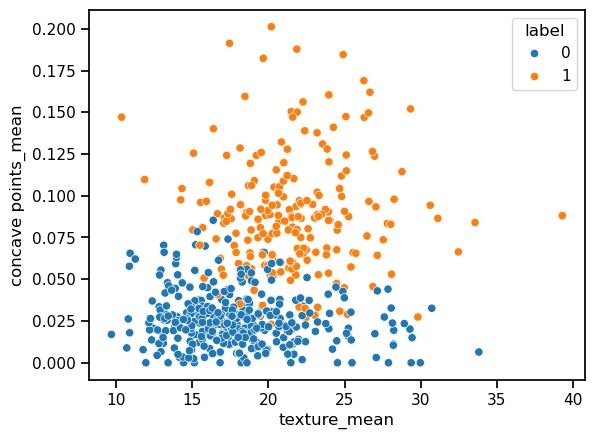

In [10]:
# let's take a look for the scatter visualization
sns.set_context('notebook', font_scale=1)
sns.scatterplot(data=tumor, x='texture_mean', y='concave points_mean', hue='label')

In [11]:
# define feature and target
x = tumor[['texture_mean', 'concave points_mean']]
y = tumor[['label']]
display(x,y)

,texture_mean,concave points_mean
0,10.38,0.14710
1,17.77,0.07017
2,21.25,0.12790
3,20.38,0.10520
4,14.34,0.10430
...,...,...
564,22.39,0.13890
565,28.25,0.09791
566,28.08,0.05302
567,29.33,0.15200


,label
0,1
1,1
2,1
3,1
4,1
...,...
564,1
565,1
566,1
567,1


In [13]:
# feature selection
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    stratify=y,
    random_state=42
)

In [52]:
# let's define the model
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train, y_train)
y_predict_class = knn.predict(x_test)
print(f'the model accuracy on data test is: ', accuracy_score(y_test, y_predict_class))

the model accuracy on data test is:  0.8111888111888111


c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [53]:
# implementing the min_max scaler
from sklearn.preprocessing import MinMaxScaler

scale = MinMaxScaler()
scale.fit(x_train) # preprocessing for scaling
x_train_scaled = scale.transform(x_train)
x_test_scaled = scale.transform(x_test)
display(x_train_scaled)

array([[0.29556983, 0.102833  ],
       [0.25836997, 0.4443837 ],
       [0.31214068, 0.06923459],
       [0.28846804, 0.06704771],
       [0.24146094, 0.03192346],
       [0.27798444, 0.02779324],
       [0.20121745, 0.13180915],
       [0.45248563, 0.09319085],
       [0.33243152, 0.10387674],
       [0.24923909, 0.41515905],
       [0.40175854, 0.29910537],
       [0.29692256, 0.07524851],
       [0.31653703, 0.21824056],
       [0.23097734, 0.20989066],
       [0.30098072, 0.12892644],
       [0.21339195, 0.16749503],
       [0.26411904, 0.45641153],
       [0.31078796, 0.527833  ],
       [0.4267839 , 0.34100398],
       [0.22624281, 0.69632207],
       [0.31552249, 0.11083499],
       [0.30571525, 0.15666004],
       [0.21001015, 0.15347913],
       [0.34697328, 0.45293241],
       [0.58741968, 0.01553181],
       [0.24146094, 0.13871769],
       [0.35847142, 0.25790258],
       [0.3902604 , 0.63568588],
       [0.0906324 , 0.18389662],
       [0.29117349, 0.06988072],
       [0.

using Min-Max Scaler in the context of KNN is primarily about ensuring that all features contribute equally to the distance calculations, thereby improving the model’s fairness, accuracy, and efficiency. This is crucial in KNN due to its reliance on distance metrics for making predictions.

In [54]:
# let's do the model fitting
knns = KNeighborsClassifier(n_neighbors=5)
knns = knns.fit(x_train_scaled, y_train)
y_predict_class = knns.predict(x_test_scaled)
print(f'the model accuracy on data test is: ', accuracy_score(y_test, y_predict_class))

the model accuracy on data test is:  0.9440559440559441


c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [65]:
k = np.arange(1,30,2)
training_accuracies = []
test_accuracies = []
score = 0

for i in k:
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train_scaled, y_train)
    
    y_predict_train = knn.predict(x_train_scaled)
    training_accuracies.append(accuracy_score(y_train, y_predict_train))
    
    y_predict_test = knn.predict(x_test_scaled)
    acc_score = accuracy_score(y_test, y_predict_test)
    test_accuracies.append(acc_score)
    
    if score < acc_score:
        score = acc_score
        best_k = i

c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples

In [66]:
df_k = pd.DataFrame(k, columns=['k'])
df_k['training_accuracy'] = pd.DataFrame(training_accuracies, columns=['temp'])
df_k['test_accuracy'] = pd.DataFrame(test_accuracies, columns=['temp'])
df_k

,k,training_accuracy,test_accuracy
0,1,1.000000,0.895105
1,3,0.938967,0.937063
2,5,0.938967,0.944056
3,7,0.938967,0.937063
4,9,0.938967,0.937063
5,11,0.941315,0.937063
6,13,0.941315,0.937063
7,15,0.941315,0.930070
8,17,0.938967,0.937063
9,19,0.936620,0.930070


In [67]:
# pd.melt
df_melted = pd.melt(df_k,id_vars=['k'],value_vars=['training_accuracy','test_accuracy'],var_name='attribute',value_name='value')
df_melted

,k,attribute,value
0,1,training_accuracy,1.000000
1,3,training_accuracy,0.938967
2,5,training_accuracy,0.938967
3,7,training_accuracy,0.938967
4,9,training_accuracy,0.938967
5,11,training_accuracy,0.941315
6,13,training_accuracy,0.941315
7,15,training_accuracy,0.941315
8,17,training_accuracy,0.938967
9,19,training_accuracy,0.936620


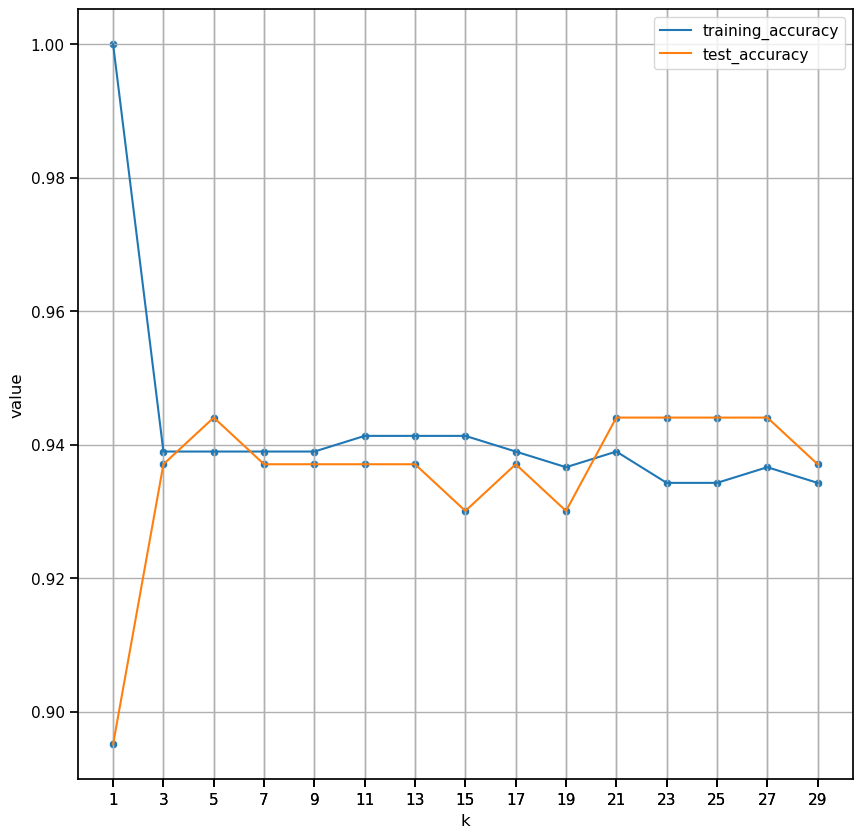

In [68]:
# plot the 2 lines
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
sns.set_context('notebook', font_scale=1)
ax = sns.lineplot(data=df_melted, x='k', y='value', hue='attribute')
sns.scatterplot(data=df_melted, x='k', y='value')
ax.set_xticks(df_melted['k'])
plt.grid()

In [69]:
print('best k:', best_k)
print('best accuracy:', score)

best k: 5
best accuracy: 0.9440559440559441
